# Phase 2: a toy Sudoku dLLM and hand-written wd1 on a MacBook

This notebook walks through phase 2 step by step.

- Most cells load committed results from `results/phase2/`. One small live demo runs on CPU if the local checkpoint exists.
- Every number traces back to a command listed in `experiments/2.x/README.md`.
- The summary with limitations is `results/phase2/SUMMARY.md`.

This is a small-scale replication exercise and not a new method.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, torch
from IPython.display import Image, display
from phase2.utils import CACHE, load_cfg
R = Path("results/phase2")
cfg = load_cfg()
HAVE_CKPT = (CACHE / "sft" / "sft_weak.pt").exists()
pd.set_option("display.precision", 3)
print("torch", torch.__version__, "| local checkpoints present:", HAVE_CKPT)

torch 2.15.0 | local checkpoints present: True


## 2.0 Data: 4×4 Sudoku split by solution grid

- There are exactly 288 valid 4×4 grids.
- They are split *by grid* into train, val and test (200/44/44). Test puzzles therefore come from solutions the model never saw.
- A puzzle hides k ∈ {6, 8, 10, 12} cells. It is kept only if its completion is unique, checked exactly against all 288 grids.

**Shows:** the task and splits are exact and leak-free.
**Does not show:** anything about difficulty at larger sizes (9×9).

In [2]:
from phase2.sudoku import enumerate_solutions, to_str, count_completions
from phase2.data import split_solutions, make_puzzles
sols = enumerate_solutions()
print("number of solved 4x4 grids:", len(sols))
print(to_str(sols[0]))
sp = split_solutions(0)
print({k: len(v) for k, v in sp.items()})
ps = make_puzzles(sp["test"][:1], 1, ks=[10], seed=0)
p = ps.puzzles[0].tolist()
print("\nA test puzzle with k=10 hidden cells (unique completion:", count_completions(p) == 1, ")")
print(to_str(p))

number of solved 4x4 grids: 288
1 2 | 3 4
3 4 | 1 2
----+----
2 1 | 4 3
4 3 | 2 1
{'train': 200, 'val': 44, 'test': 44}

A test puzzle with k=10 hidden cells (unique completion: True )
. 4 | . 1
. 2 | . .
----+----
4 . | 1 .
. . | . 4


In [3]:
pd.read_csv(R / "data_stats.csv").pivot(index="k", columns="split", values="n_puzzles")

split,test,train,val
k,,,
6,176,4000,44
7,176,4000,44
8,176,4000,44
9,176,4000,44
10,176,4000,44
11,176,3813,44
12,138,1819,41


## 2.1 Masked-diffusion training and the weak checkpoint

- Model: a 0.8M-param bidirectional transformer trained with the LLaDA/MDLM loss.
- The weak checkpoint is chosen on val only: val solve rate in [0.3, 0.6], closest to 0.45. The result is step 120 (val 0.42).
- The weak window is narrow. The model goes from 11% to 98% val within about 100 steps, so the weak model is a mid-transition snapshot.

**Shows:** the training recipe works and gives a reproducible starting point for RL.
**Does not show:** that this weak model resembles a weak *large* model.

The first attempt (positions only, without row/column/box embeddings) plateaued:

{
 "weak_step": 120,
 "weak_val_solve": 0.4196721315383911,
 "rule": "val solve rate in [0.3, 0.6], closest to midpoint 0.44999999999999996",
 "full_step": 20000,
 "full_val_solve": 1.0,
 "eval_sampler": "confidence, S=8, greedy",
 "n_params": 798212,
 "wall_clock_s": 778.5065770149231,
 "overrides": [],
 "seed": 0,
 "ckpt_dir": "/Users/giovannigiofre/dllm-cache/phase2/sft"
}


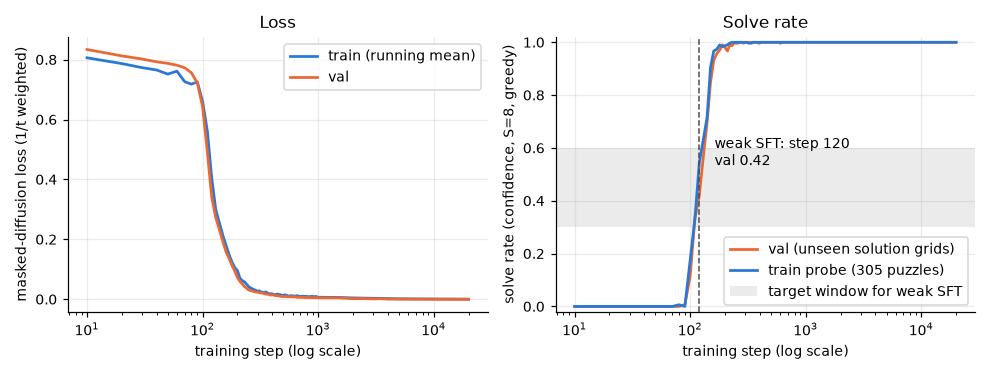

In [4]:
print(json.dumps({k: v for k, v in json.load(open(R / "sft_selection.json")).items() if k != "env"}, indent=1))
display(Image(R / "sft_training_curve.png"))

In [5]:
att = pd.read_csv(R / "sft_attempts" / "attempt1_learnedpos_lr3e-4_20k.csv")
print("failed attempt 1 (plain learned positions): best val solve", att.val_solve.max(), "after", att.step.max(), "steps")

failed attempt 1 (plain learned positions): best val solve 0.14098361134529114 after 20000 steps


## 2.2 Unmasking strategy × step budget

Test solve rate is measured for each unmasking strategy at each step budget S (greedy decoding).

- For the weak model, the order in which cells are committed matters a lot. At S = 8: confidence 0.48, random 0.14.
- More steps also help: one-shot decoding solves only 1.8%.
- The fully trained model solves everything in one step regardless of strategy.

**Shows:** confidence-ordered multi-step decoding is what makes a partially trained denoiser usable.
**Does not show:** that the ranking carries over to LLaDA-8B.

,ckpt,strategy,1,2,4,8,16
0,sft_full,confidence,0.998,1.000,1.000,1.000,1.000
1,sft_full,entropy,0.998,1.000,1.000,1.000,1.000
2,sft_full,margin,0.998,1.000,1.000,1.000,1.000
3,sft_full,random,0.998,0.999,0.999,0.999,1.000
4,sft_weak,confidence,0.018,0.077,0.282,0.482,0.559
5,sft_weak,entropy,0.018,0.075,0.220,0.397,0.461
6,sft_weak,margin,0.018,0.076,0.289,0.479,0.539
7,sft_weak,random,0.018,0.058,0.102,0.142,0.147


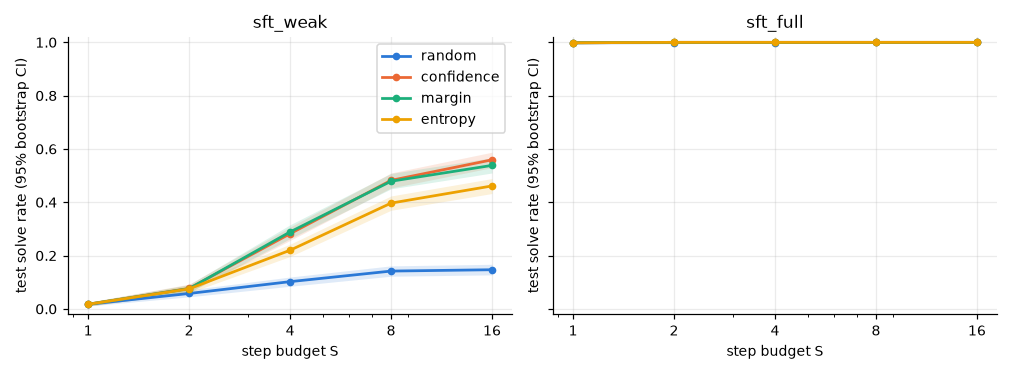

In [6]:
display(pd.read_csv(R / "strategies_table.csv"))
display(Image(R / "strategies_solve_rate.png"))

### Live demo: how the weak model fills a puzzle

The demo runs a greedy confidence-ordered decode with S = 16. It prints:

- the step at which each cell was committed;
- the committed probability for each cell.

Compare the commit order with how constrained each cell is. This is a single example, not a measurement.

In [7]:
if HAVE_CKPT:
    from phase2.analysis import load
    from phase2.sampler import sample
    m = load(cfg, CACHE / "sft" / "sft_weak.pt", "cpu")
    pz = make_puzzles(sp["test"][:1], 1, ks=[12], seed=1).puzzles
    out = sample(m, pz, 16, "confidence", 0.0)
    order = out.commit_step[0].view(4, 4)
    print("puzzle:"); print(to_str(pz[0].tolist()))
    print("\nweak-SFT completion (greedy, confidence, S=16):"); print(to_str(out.grid[0].tolist()))
    print("\ncommit step per cell (-1 = given):"); print(order.numpy())
    print("\ncommit confidence:"); print(np.round(out.commit_conf[0].view(4, 4).numpy(), 2))
else:
    print("checkpoint not present locally; skipping live demo")

puzzle:
. . | 2 .
1 . | . .
----+----
4 . | . .
. . | 3 .

weak-SFT completion (greedy, confidence, S=16):
3 4 | 2 1
1 2 | 4 3
----+----
4 3 | 1 2
2 1 | 3 4

commit step per cell (-1 = given):
[[ 4  8 -1  5]
 [-1  7  3  6]
 [-1  1 11 10]
 [ 0  2 -1  9]]

commit confidence:
[[0.53 0.76  nan 0.73]
 [ nan 0.61 0.68 0.73]
 [ nan 0.66 0.7  0.71]
 [0.62 0.78  nan 0.5 ]]


## 2.3 RL with wd1 vs positive-only (3 seeds each), and the τ sweep

- All RL runs start from the weak SFT checkpoint and run 500 steps (B = 32 puzzles × G = 8 rollouts, binary reward). Each takes about 1 minute on MPS.
- **wd1 (τ = 1):** improves smoothly to 0.738 ± 0.005 test.
- **Positive-only (w⁻ = 0):**
  - First collapses in every seed: val drops from 0.42 to about 0.10 within 150 steps.
  - Meanwhile it becomes *more* confident in its own rollouts (right panel). This is the instability wd1's negative term is meant to prevent.
  - It then recovers and ends at 0.932 ± 0.016, clearly above wd1.
- **τ:** the τ sweep shows wd1 is insensitive to τ ∈ {0.5, 1, 2}.

**Shows:**
- wd1 avoids the early collapse.
- wd1 lifts the weak model from 0.48 to 0.74.

**Does not show:**
- That positive-only ends worse: here it ends better at 500 steps. This contradicts the paper's claim. Possible reasons include the toy setting, binary rewards, and the absence of a KL term; none of them is tested.
- Behaviour beyond 500 steps.

,variant,tau,n,final_val_mean,final_val_std,final_test_mean,final_test_std,best_test_mean,best_test_std
0,positive_only,1.0,3,0.944,0.017,0.932,0.016,0.932,0.016
1,wd1,0.5,3,0.725,0.000,0.740,0.009,0.741,0.007
2,wd1,1.0,3,0.731,0.015,0.738,0.005,0.738,0.005
3,wd1,2.0,3,0.737,0.015,0.743,0.009,0.729,0.013


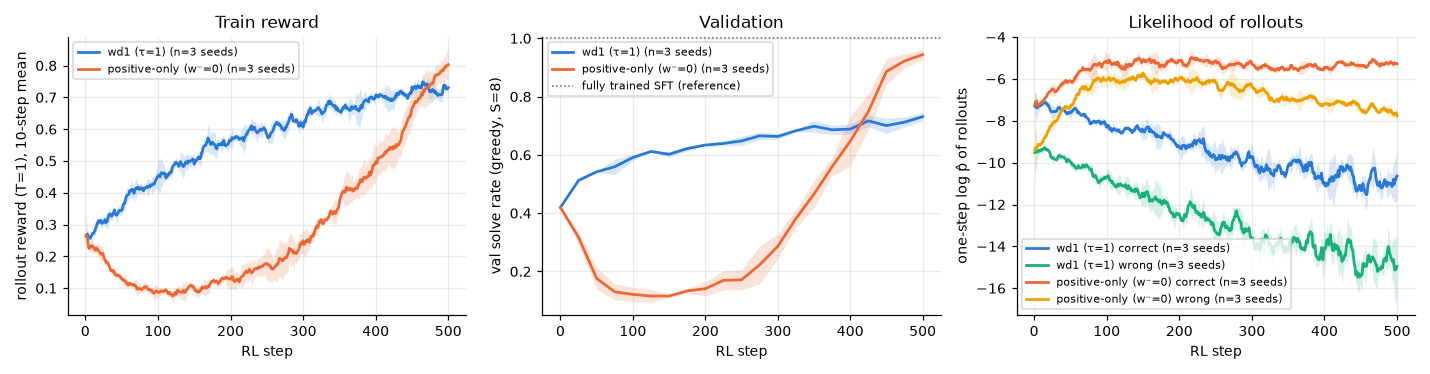

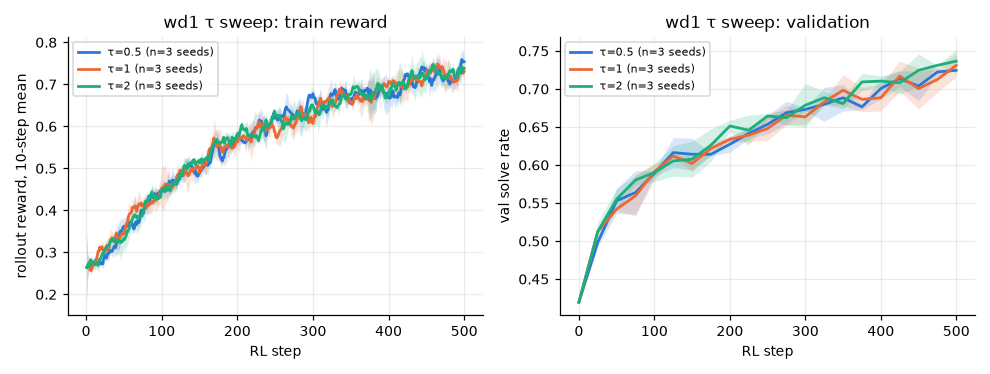

In [8]:
display(pd.read_csv(R / "rl_summary.csv"))
display(Image(R / "rl_wd1_vs_positive_only.png"))
display(Image(R / "rl_tau_sweep.png"))

### Sanity check: is the one-step likelihood a usable proxy?

- wd1 needs log p(completion). This implementation uses a single forward pass with all non-given cells masked.
- The check compares it with a sequential estimate that reveals one cell per pass, in row-major order.
- Result: Spearman ≈ 0.86 on weak SFT and 0.79 after RL. The one-step estimate is biased low by 3–5 nats.

**Shows:** a rank-correlated proxy, good enough for weighting.
**Does not show:** that it is unbiased, or the best estimator.

{
 "sft_weak": {
  "n": 256,
  "frac_correct": 0.28515625,
  "sec_sequential": 0.1657869815826416,
  "sec_one_step": 0.0008411407470703125,
  "pearson_one_step_p0": 0.7997185309925614,
  "spearman_one_step_p0": 0.8551930753035348,
  "pearson_percell_one_step_p0": 0.6118786809864123,
  "pearson_one_step_p015": 0.7551596886089532,
  "spearman_one_step_p015": 0.8009468740629359,
  "pearson_percell_one_step_p015": 0.48295309480075926,
  "pearson_one_step_p015_avg16": 0.8161006215372764,
  "spearman_one_step_p015_avg16": 0.8561730537631486,
  "pearson_percell_one_step_p015_avg16": 0.6026362021541257,
  "mean_seq_minus_one_step_p0": 2.753927707672119
 },
 "rl_best": {
  "n": 256,
  "frac_correct": 0.71875,
  "sec_sequential": 0.07465481758117676,
  "sec_one_step": 0.0006318092346191406,
  "pearson_one_step_p0": 0.7117160194010452,
  "spearman_one_step_p0": 0.7947762942224794,
  "pearson_percell_one_step_p0": 0.6506786403264718,
  "pearson_one_step_p015": 0.6364298135973503,
  "spearman_one_s

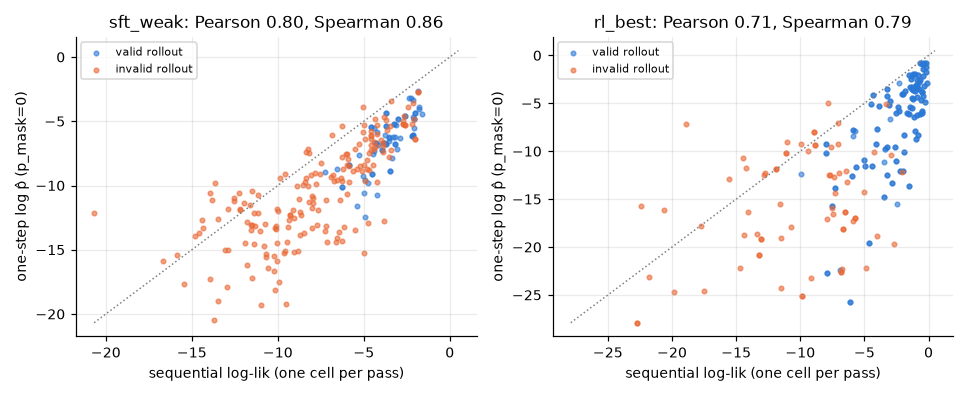

In [9]:
print(json.dumps(json.load(open(R / "likelihood_estimators.json")), indent=1))
display(Image(R / "likelihood_estimators.png"))

## 2.4 Calibration before and after RL

Setup: test set, greedy decoding, S = 8.

- *Cell confidence* = the probability of the committed value. *Puzzle confidence* = the mean of its cell confidences.
- ECE uses 10 bins. AUROC measures how well confidence separates right from wrong.

Results:

- **Weak SFT:** slightly under-confident (cell conf 0.72 vs acc 0.76, ECE 0.045).
- **wd1:** over-confident (0.95 vs 0.88, ECE ≈ 0.06–0.07). AUROC improves a little (cell 0.62 → 0.65, puzzle 0.82 → 0.86).
- **Positive-only:** under-confident, but discriminates best (cell AUROC 0.73, puzzle ECE 0.05).

**Shows:** RL improves ranking but can shift the model's confidence level. wd1 here pushes it towards over-confidence.
**Does not show:** calibration at other temperatures or budgets, or at scale.

,ckpt,solve_rate,cell_acc,mean_cell_conf,cell_ece,cell_auroc,mean_puzzle_conf,puzzle_ece,puzzle_auroc,conf_correct_cells,conf_wrong_cells,n_cells,n_puzzles
0,sft_weak,0.482,0.760,0.715,4.525e-02,0.618,0.721,2.509e-01,0.816,0.727,0.678,10632,1194
1,rl_best,0.735,0.876,0.949,7.305e-02,0.658,0.951,2.158e-01,0.881,0.955,0.908,10632,1194
2,sft_full,1.000,1.000,1.000,8.941e-07,NaN,1.000,1.013e-06,NaN,1.000,NaN,10632,1194


solve_rate        mean_cell_conf        cell_ece         \
                            mean    std           mean    std     mean    std   
group                                                                           
rl_positive_only_tau1      0.932  0.016          0.899  0.010    0.066  0.002   
rl_wd1_tau0.5              0.741  0.007          0.947  0.002    0.061  0.002   
rl_wd1_tau1                0.738  0.005          0.945  0.006    0.063  0.009   
rl_wd1_tau2                0.729  0.013          0.944  0.004    0.064  0.003   

                      cell_auroc        puzzle_ece        puzzle_auroc         
                            mean    std       mean    std         mean    std  
group                                                                          
rl_positive_only_tau1      0.733  0.005      0.051  0.004        0.931  0.014  
rl_wd1_tau0.5              0.642  0.016      0.208  0.006        0.858  0.007  
rl_wd1_tau1                0.654  0.011      0.209  0.006        0.875  0.005  
rl_wd1_tau2                0.646  0.004      0.217  0.009        0.857  0.018

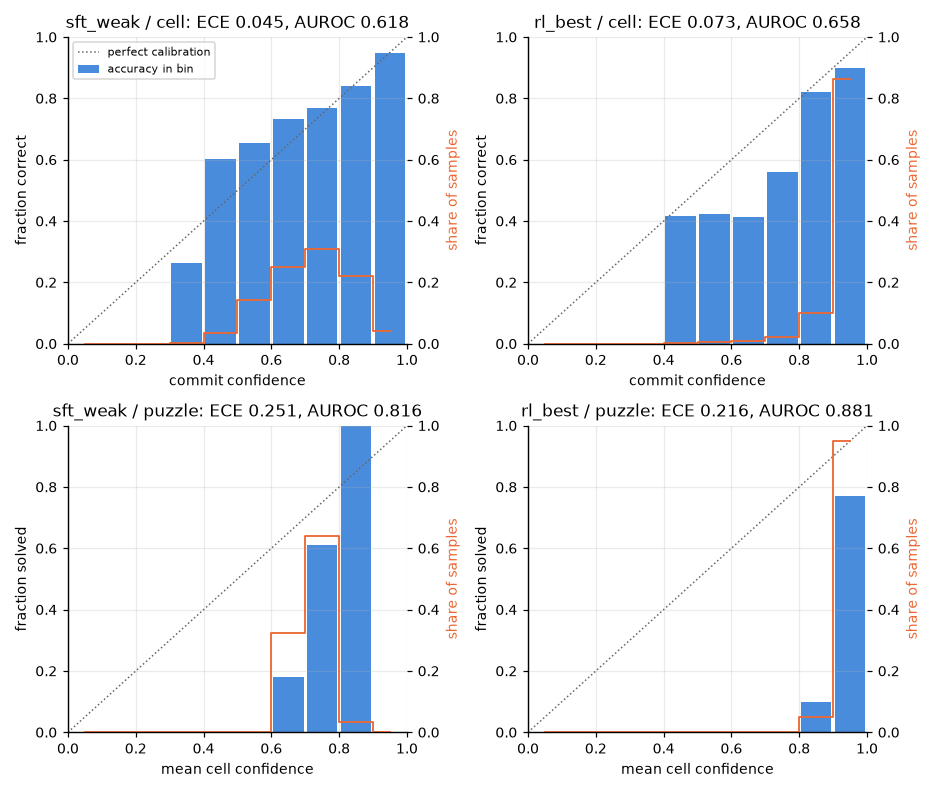

In [10]:
cal = pd.read_csv(R / "calibration.csv")
display(cal[cal.ckpt.isin(["sft_weak", "rl_best", "sft_full"])])
rl = cal[cal.ckpt.str.startswith("rl_wd1") | cal.ckpt.str.startswith("rl_positive")].copy()
rl["group"] = rl.ckpt.str.replace(r"_seed\d+", "", regex=True)
display(rl.groupby("group")[["solve_rate", "mean_cell_conf", "cell_ece", "cell_auroc", "puzzle_ece", "puzzle_auroc"]].agg(["mean", "std"]))
display(Image(R / "calibration_before_after.png"))

## 2.5 Takeaways and limits

- The mechanics are implemented from scratch and tested: masked-diffusion loss, confidence-ordered unmasking, wd1 weights and sign, and the one-step likelihood.
- On this toy task:
  - decoding order matters;
  - wd1 is stable and helps;
  - positive-only collapses early but ends ahead at 500 steps.
- The task is tiny, rewards are binary, RL uses no KL term, and runs use 3 seeds × 500 steps.
- These results say nothing direct about LLaDA-8B-scale RL. See `results/phase2/SUMMARY.md`.